In [1]:
import mne
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as mp
from glob import glob
from pathlib import Path
from scipy.ndimage import zoom
from PIL import Image
import os
import re
from mne_connectivity import spectral_connectivity_epochs
from scipy.signal import hilbert
from scipy.signal import coherence
from pyinform.transferentropy import transfer_entropy
from sklearn.metrics import mutual_info_score
from sklearn.feature_selection import mutual_info_regression
from scipy.stats import rankdata, norm
from numpy.linalg import inv, solve

In [2]:
#Custom folder where you want the dataset
data_dir=Path(r"H:\EEG_Dataset\Data\S")
data_dir1=Path(r"H:\EEG_Dataset\Data\H")

edf_files=sorted(data_dir.glob("*.edf"))
edf_files1=sorted(data_dir1.glob("*.edf"))

print(f"Found {len(edf_files)} EDF files")
print(f"Found {len(edf_files1)} EDF files")

scz_raw_list=[]
hc_raw_list=[]

for edf_file in edf_files:
    scz_raw=mne.io.read_raw_edf(edf_file, preload=True)
    scz_raw.pick_types(eeg=True)
    scz_raw_list.append(scz_raw)

for edf_file1 in edf_files1:
    hc_raw=mne.io.read_raw_edf(edf_file1, preload=True)
    hc_raw.pick_types(eeg=True)
    hc_raw_list.append(hc_raw)
    
#Combine all the files
#scz_raw_combined=mne.concatenate_raws(scz_raw_list)

Found 14 EDF files
Found 14 EDF files
Extracting EDF parameters from H:\EEG_Dataset\Data\S\s01.edf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 211249  =      0.000 ...   844.996 secs...
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
Extracting EDF parameters from H:\EEG_Dataset\Data\S\s02.edf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 286249  =      0.000 ...  1144.996 secs...
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
Extracting EDF parameters from H:\EEG_Dataset\Data\S\s03.edf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 240999  =      0.000 ...   963.996 secs...
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
Extracting EDF parameters from H:\EEG_Dataset\Data\S\s04.edf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 301249  =      0.000 ...  1204

In [3]:
scz_raw_list[0]

<RawEDF | s01.edf, 19 x 211250 (845.0 s), ~30.6 MiB, data loaded>

In [4]:
#Show info
print(scz_raw_list[0].info)
print(hc_raw_list[0].info)

#Check no. of samples
print(scz_raw_list[0].n_times)
print(hc_raw_list[0].n_times)

<Info | 8 non-empty values
 bads: []
 ch_names: Fp2, F8, T4, T6, O2, Fp1, F7, T3, T5, O1, F4, C4, P4, F3, C3, ...
 chs: 19 EEG
 custom_ref_applied: False
 highpass: 0.0 Hz
 lowpass: 125.0 Hz
 meas_date: 2004-08-20 12:19:24 UTC
 nchan: 19
 projs: []
 sfreq: 250.0 Hz
 subject_info: <subject_info | his_id: OJS>
>
<Info | 8 non-empty values
 bads: []
 ch_names: Fp2, F8, T4, T6, O2, Fp1, F7, T3, T5, O1, F4, C4, P4, F3, C3, ...
 chs: 19 EEG
 custom_ref_applied: False
 highpass: 0.0 Hz
 lowpass: 125.0 Hz
 meas_date: 2003-06-23 16:14:37 UTC
 nchan: 19
 projs: []
 sfreq: 250.0 Hz
 subject_info: <subject_info | his_id: DJZ>
>
211250
231250


In [5]:
#Set EEG sensors positions for referencing and visualization
#Set standard 10-20 montage
montage=mne.channels.make_standard_montage('standard_1020')
for i in range(14):
    scz_raw_list[i].set_montage(montage, on_missing='warn')
    hc_raw_list[i].set_montage(montage, on_missing='warn')

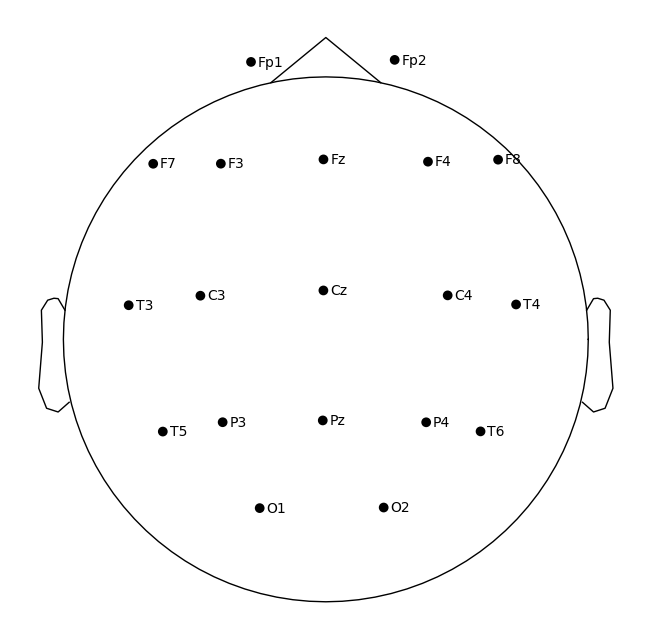

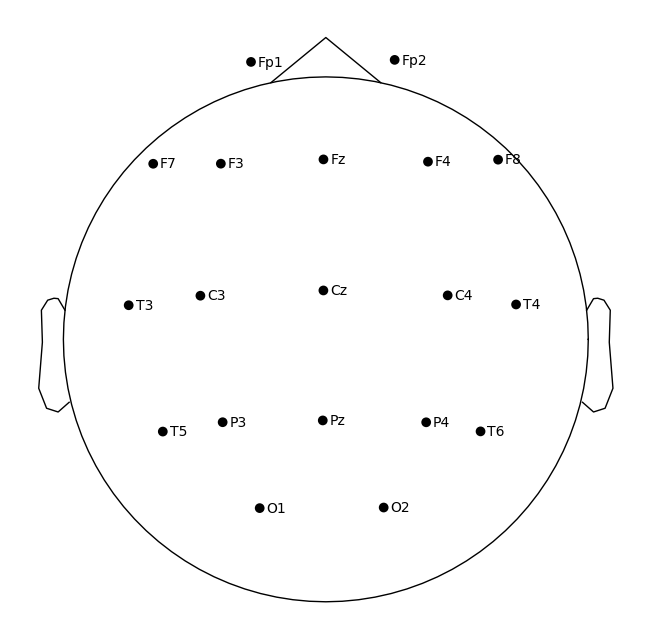

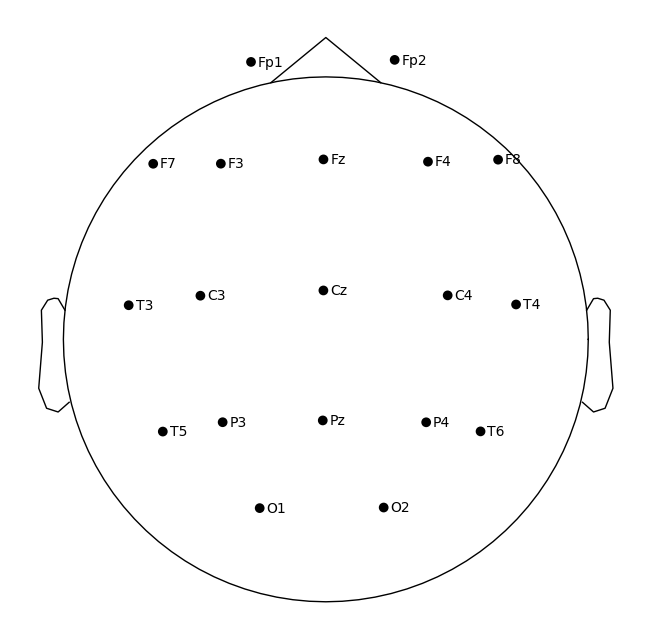

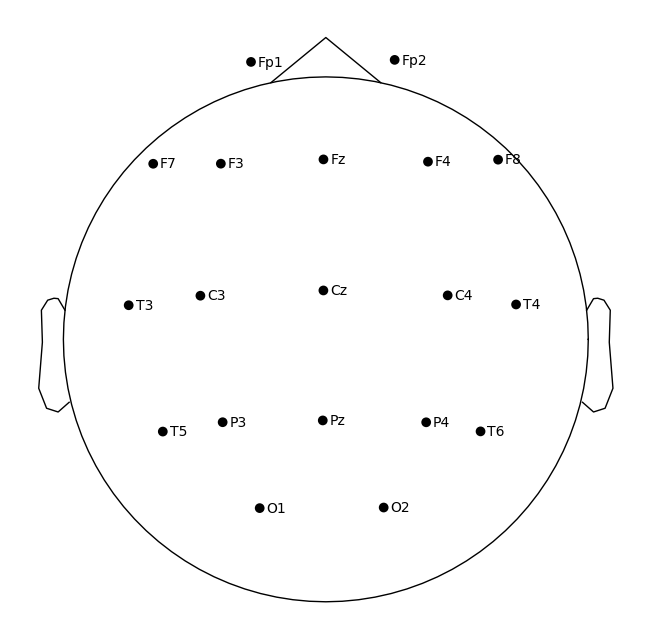

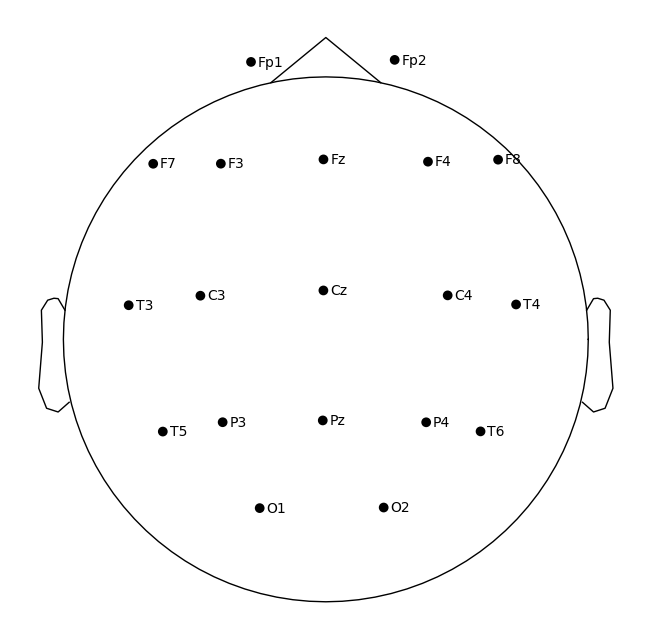

...

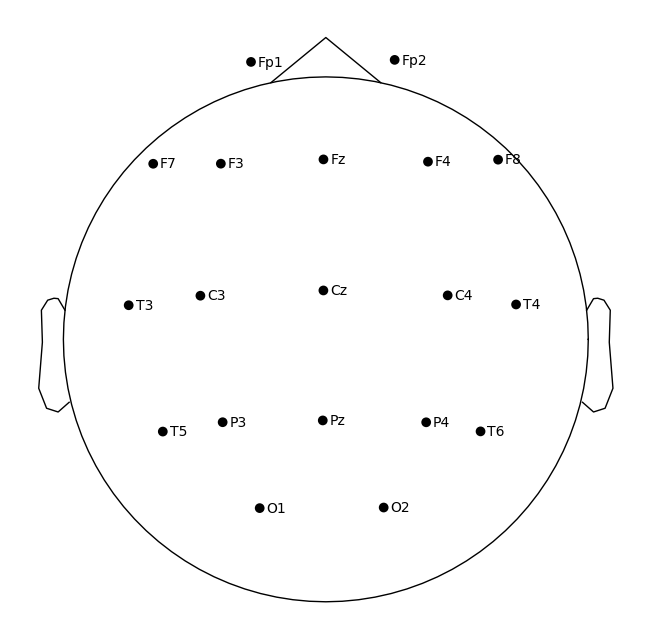

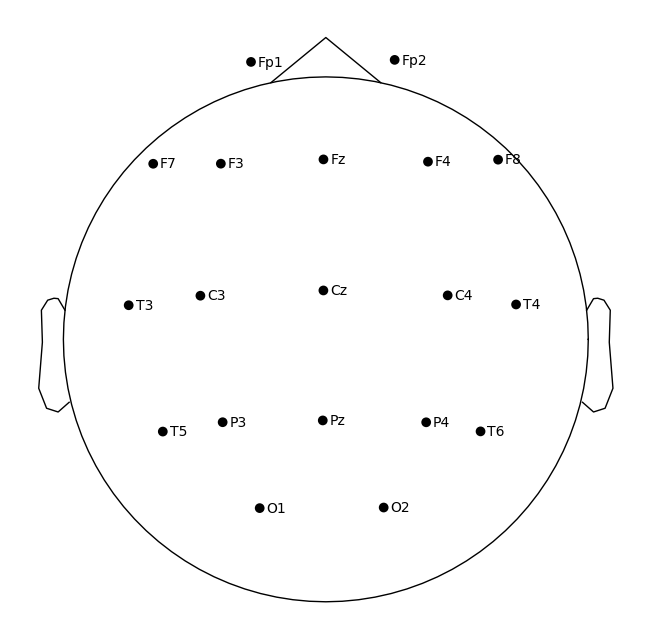

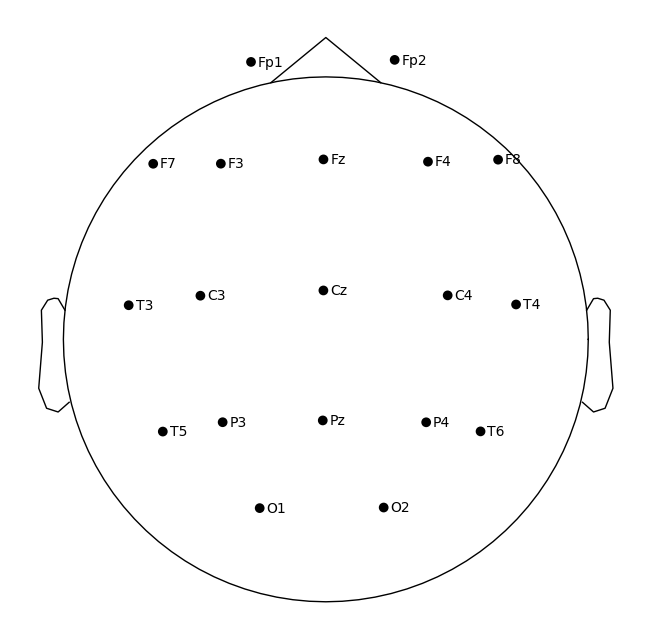

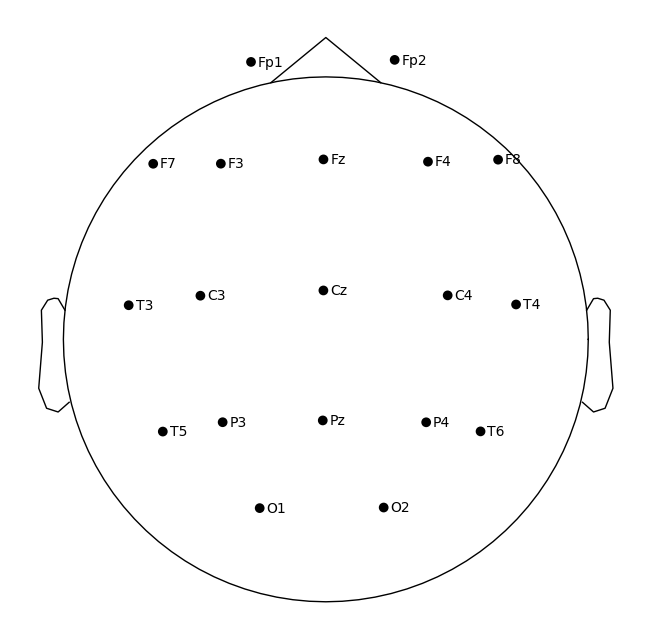

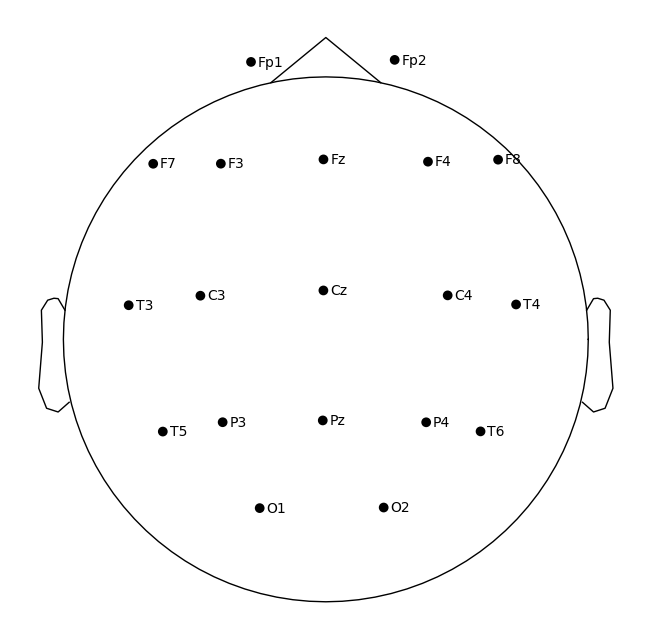

In [6]:
#Check the montage
for i in range(14):
    scz_raw_list[i].plot_sensors(kind='topomap', show_names=True)
    hc_raw_list[i].plot_sensors(kind='topomap', show_names=True)
    mp.show()

In [7]:
scz_epochs=[]
hc_epochs=[]
for i in range(14):
    epochs=mne.make_fixed_length_epochs(scz_raw_list[i], duration=30.0, preload=True)
    scz_epochs.append(epochs)
    epochs1=mne.make_fixed_length_epochs(hc_raw_list[i], duration=30.0, preload=True)
    hc_epochs.append(epochs1)

Not setting metadata
28 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 28 events and 7500 original time points ...
0 bad epochs dropped
Not setting metadata
30 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 30 events and 7500 original time points ...
0 bad epochs dropped
Not setting metadata
38 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 38 events and 7500 original time points ...
0 bad epochs dropped
Not setting metadata
30 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 30 events and 7500 original time points ...
0 bad epochs dropped
Not setting metadata
32 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 32 events and 7500 original time points 

Using matplotlib as 2D backend.


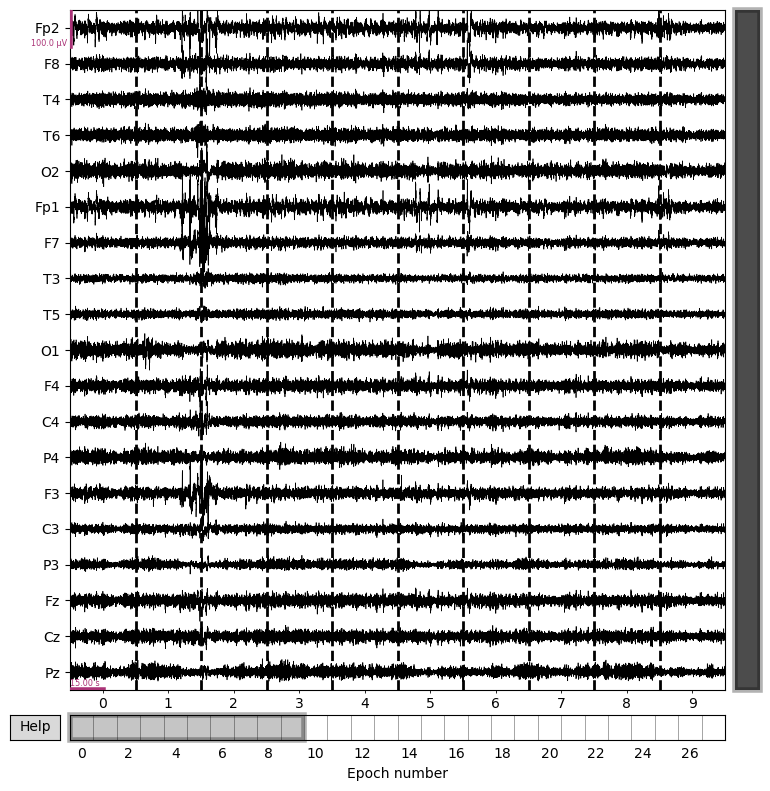

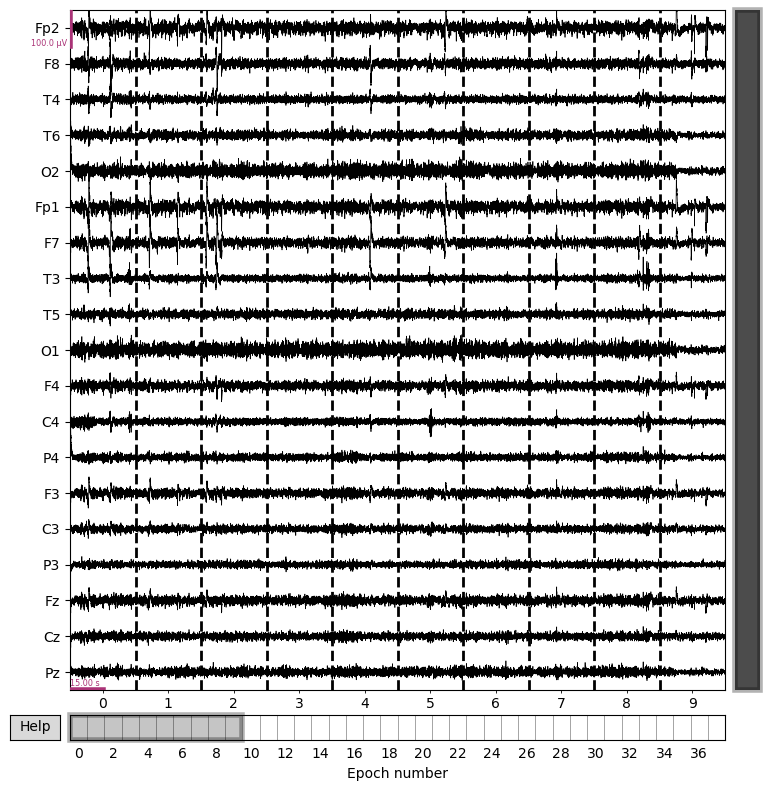

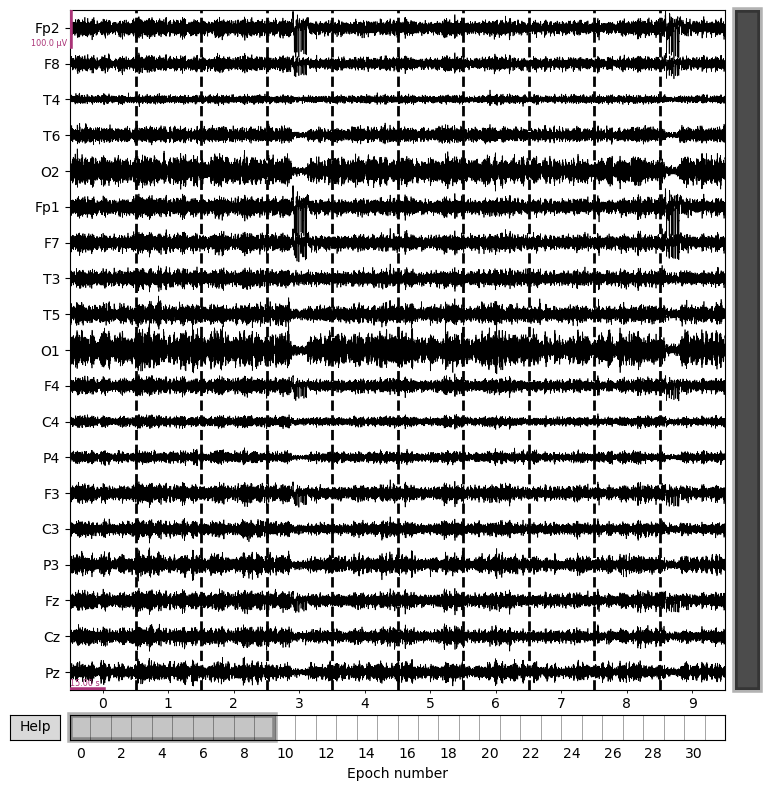

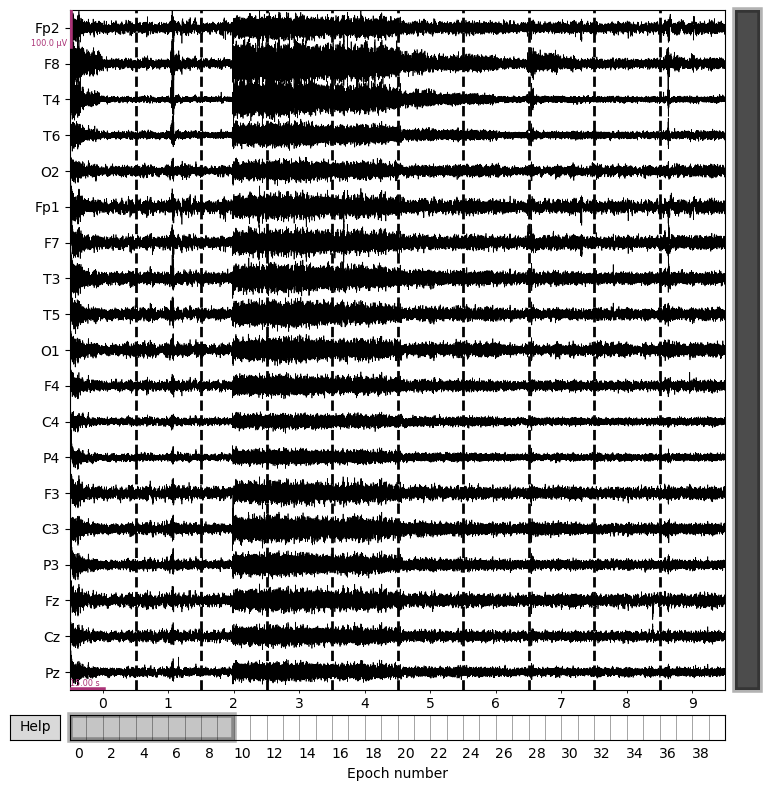

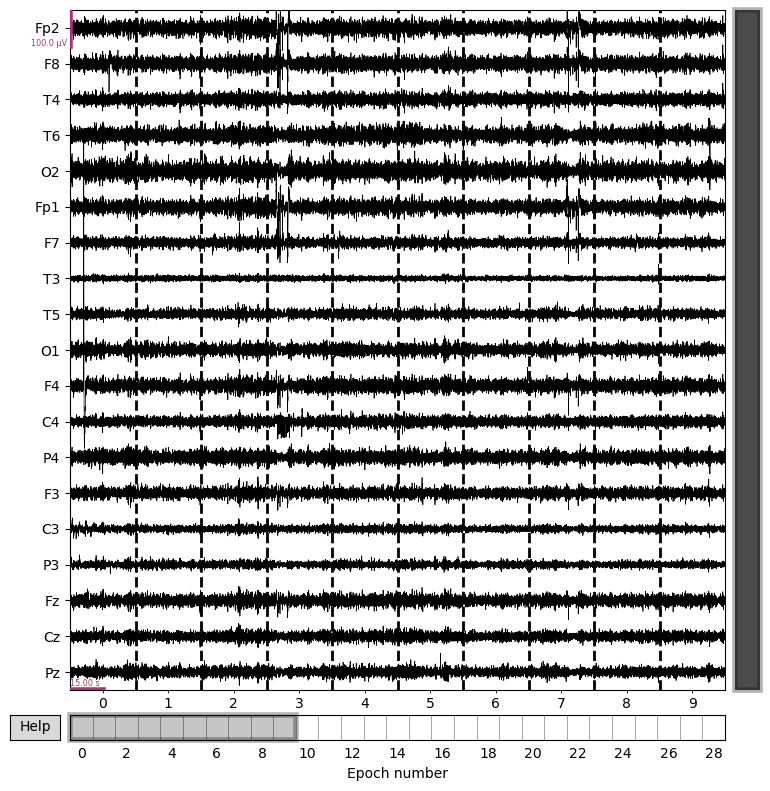

...

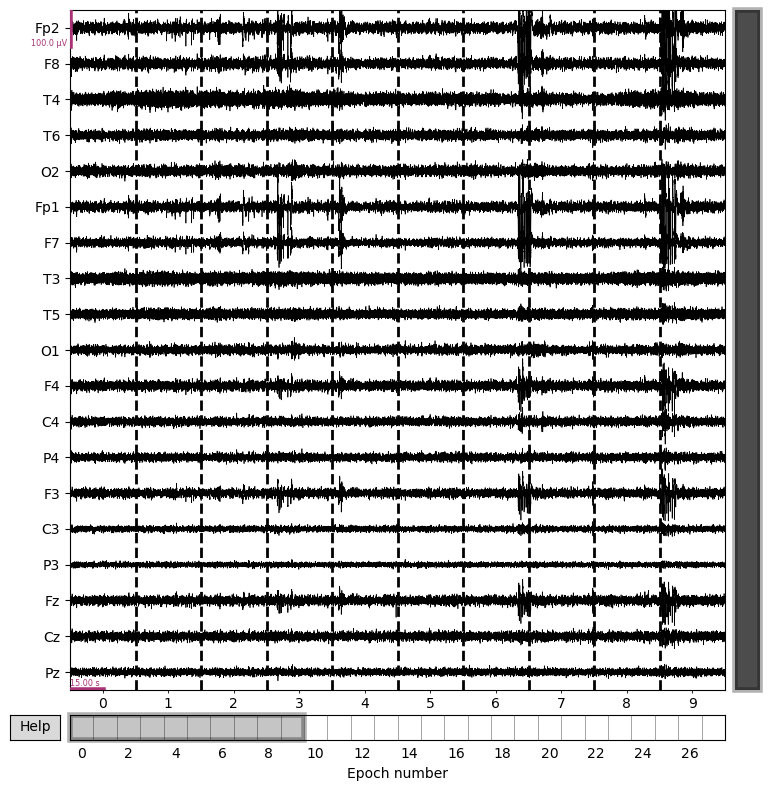

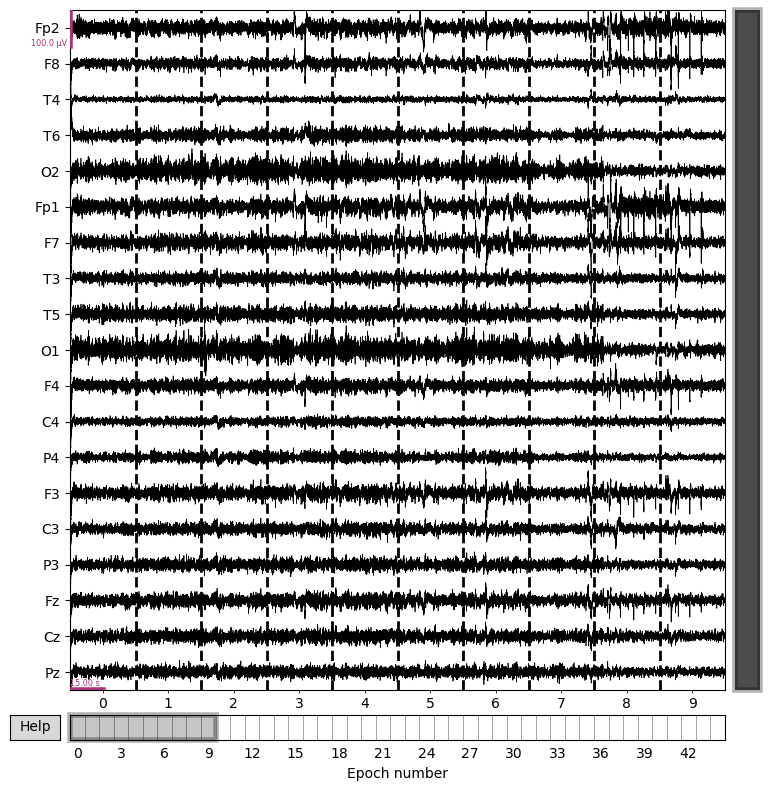

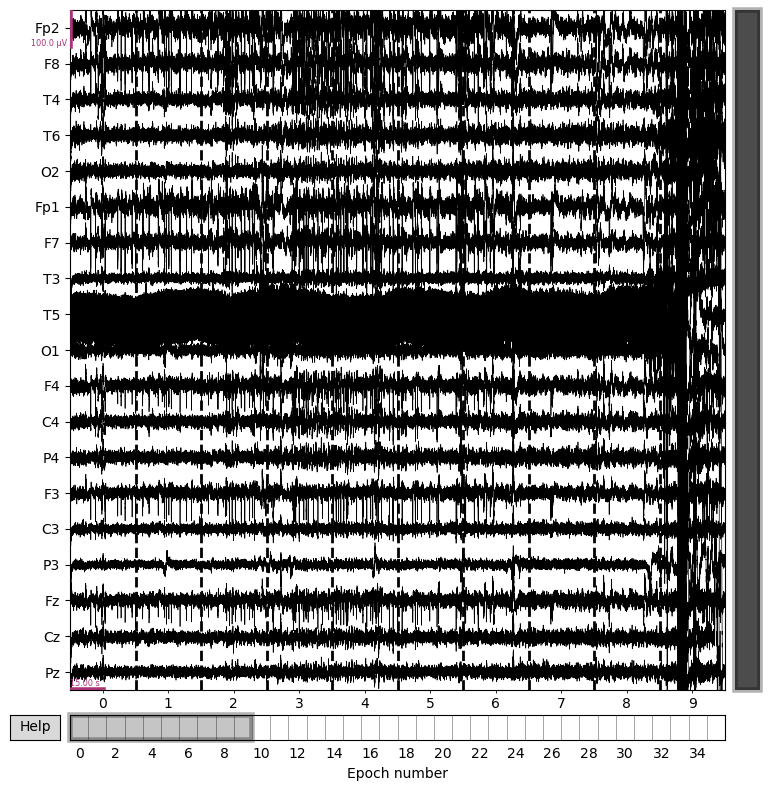

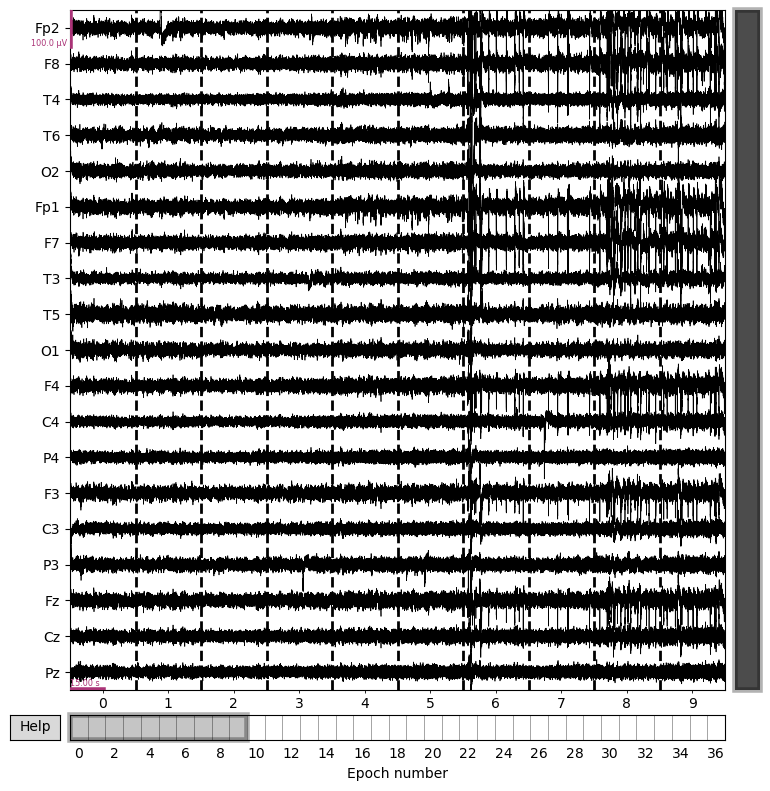

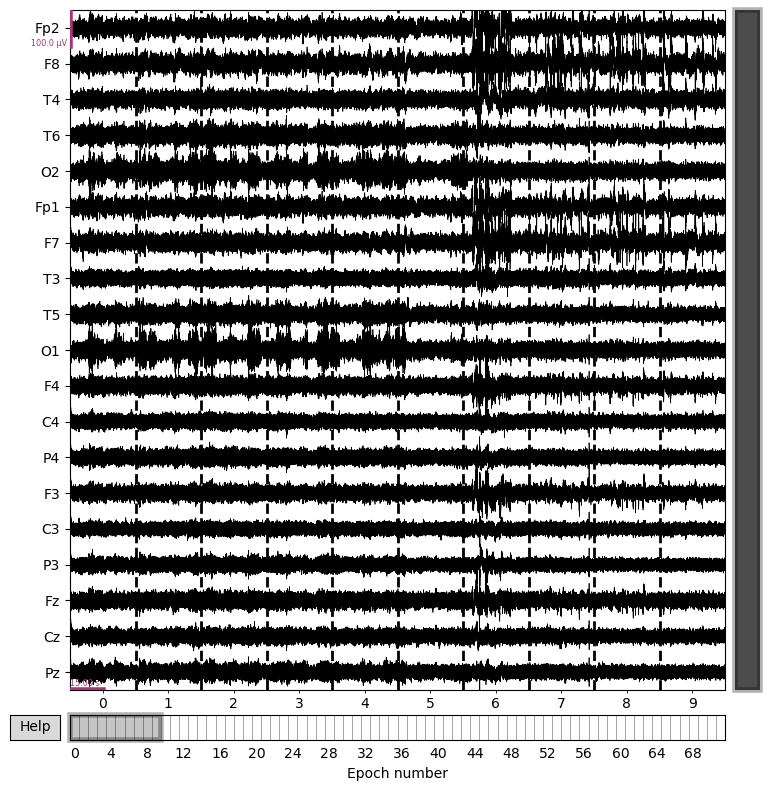

In [8]:
for i in range(14):
    scz_epochs[i].plot(n_epochs=10, scalings=dict(eeg=50e-6), block=True)

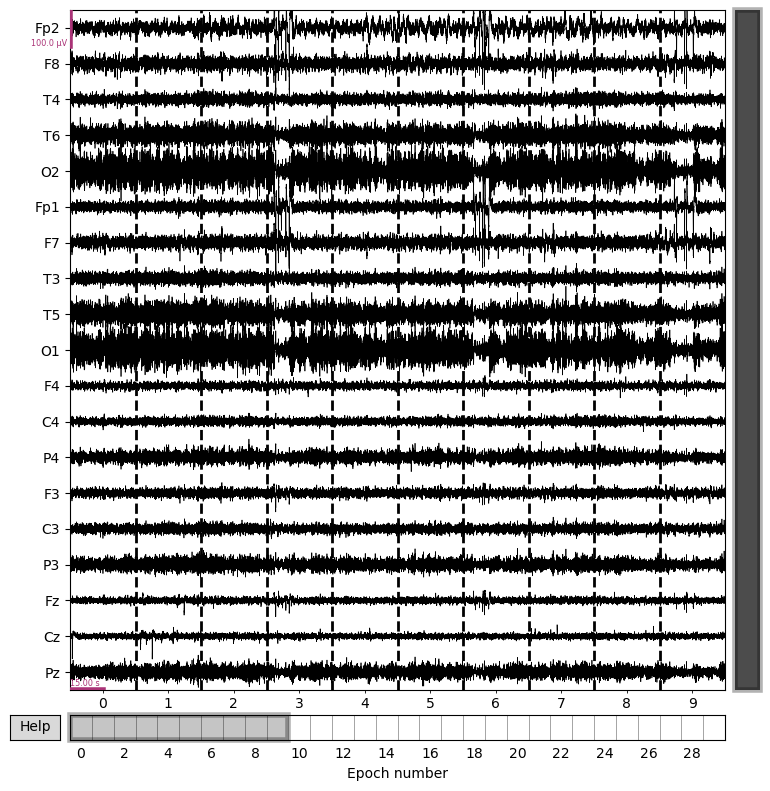

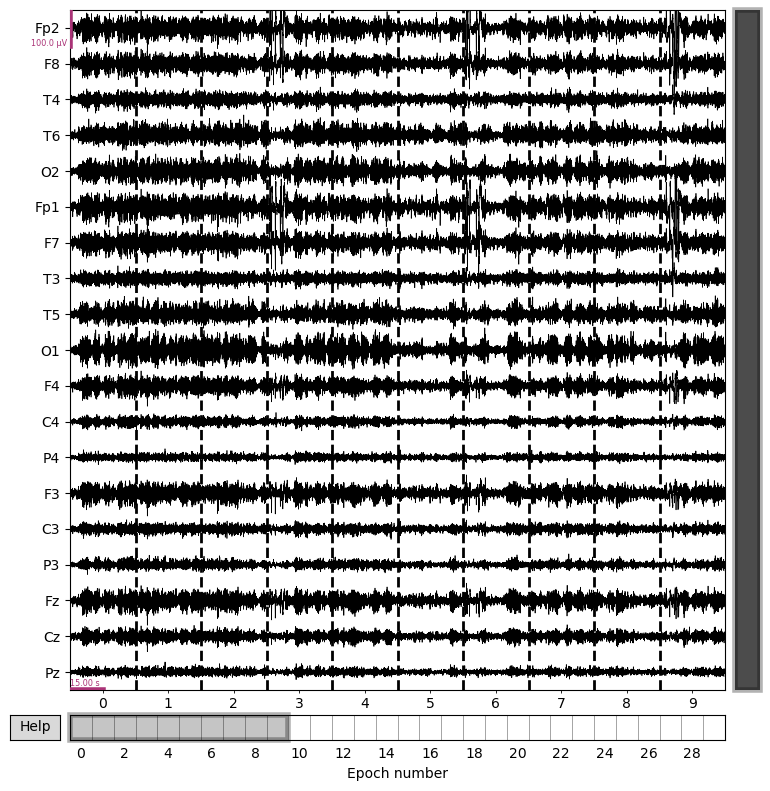

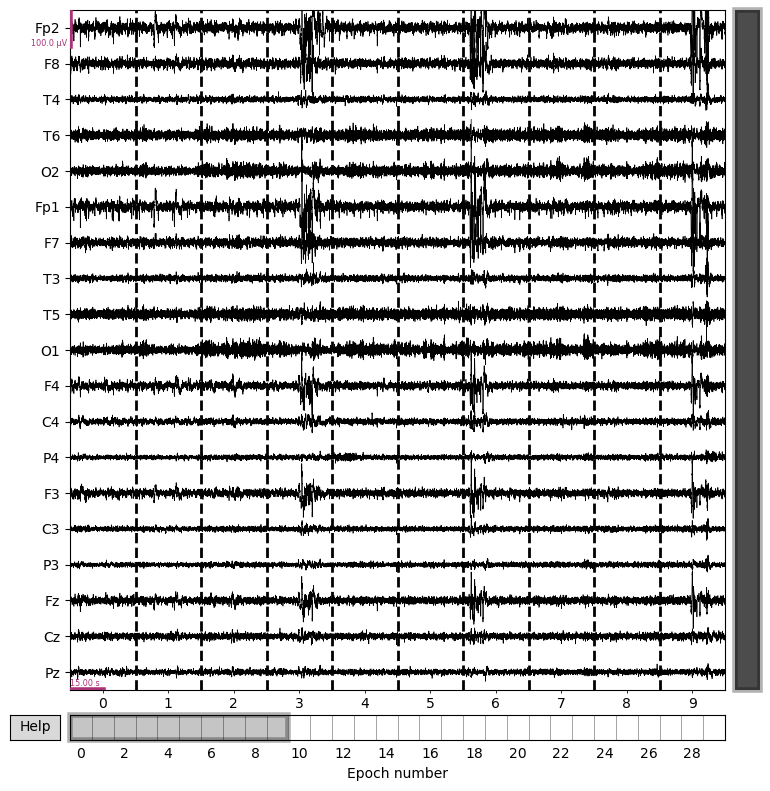

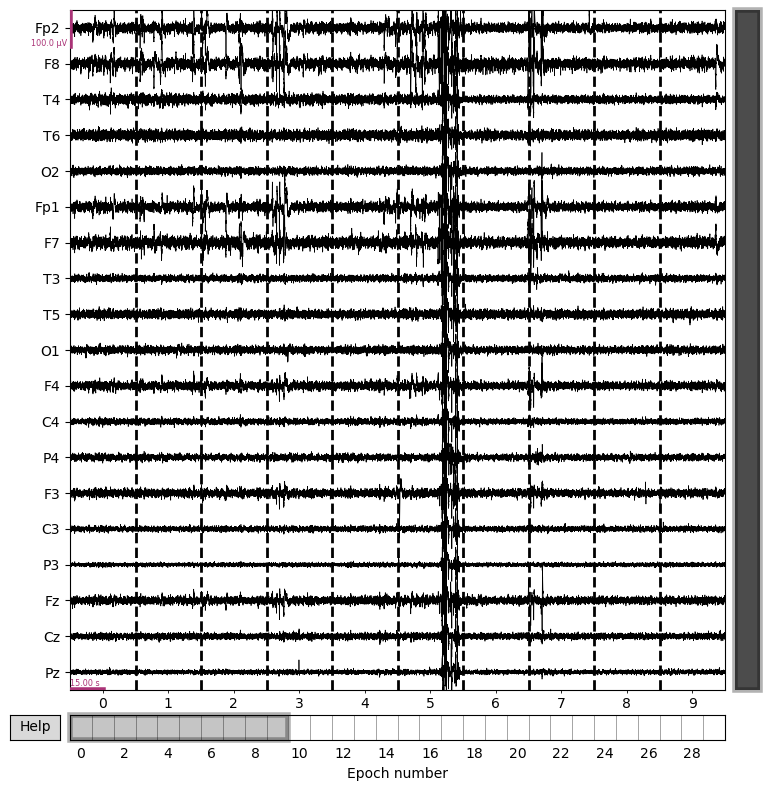

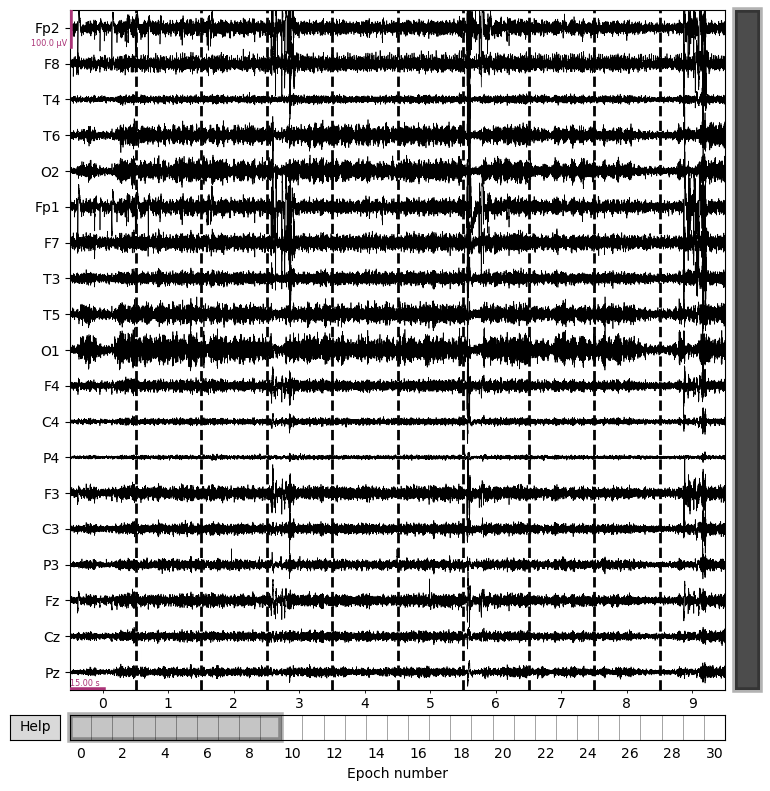

...

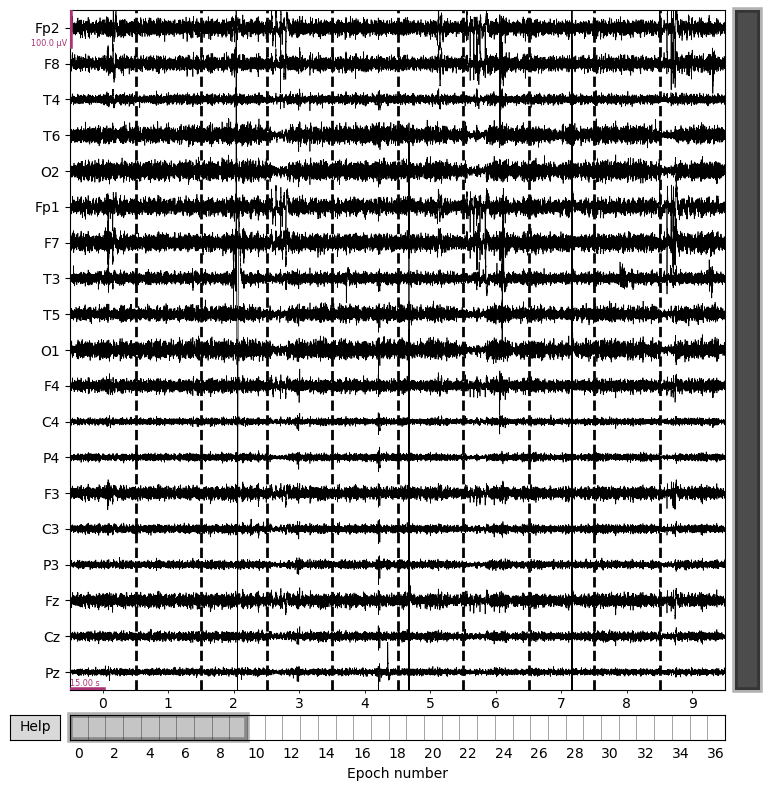

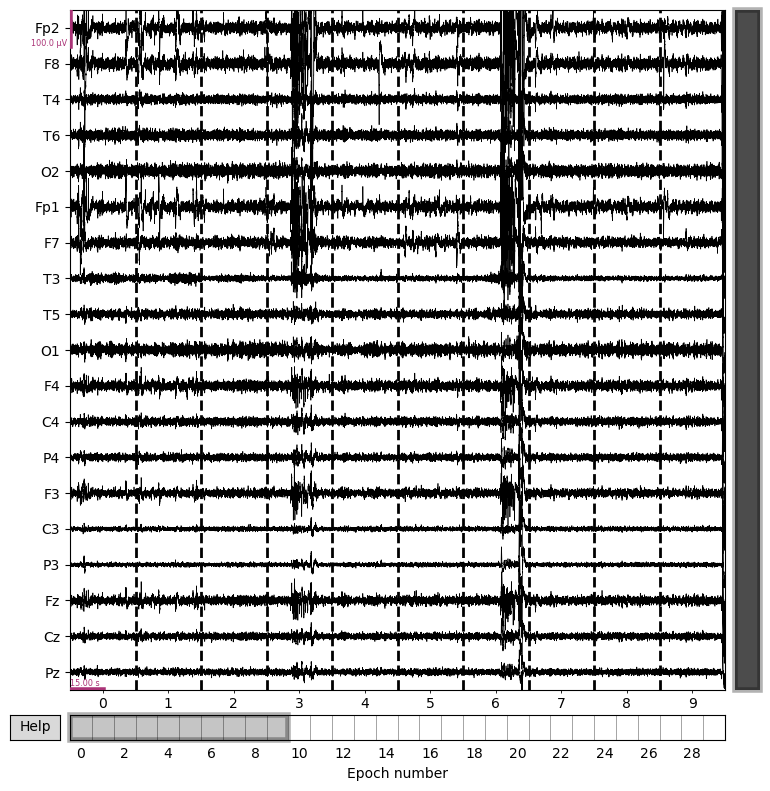

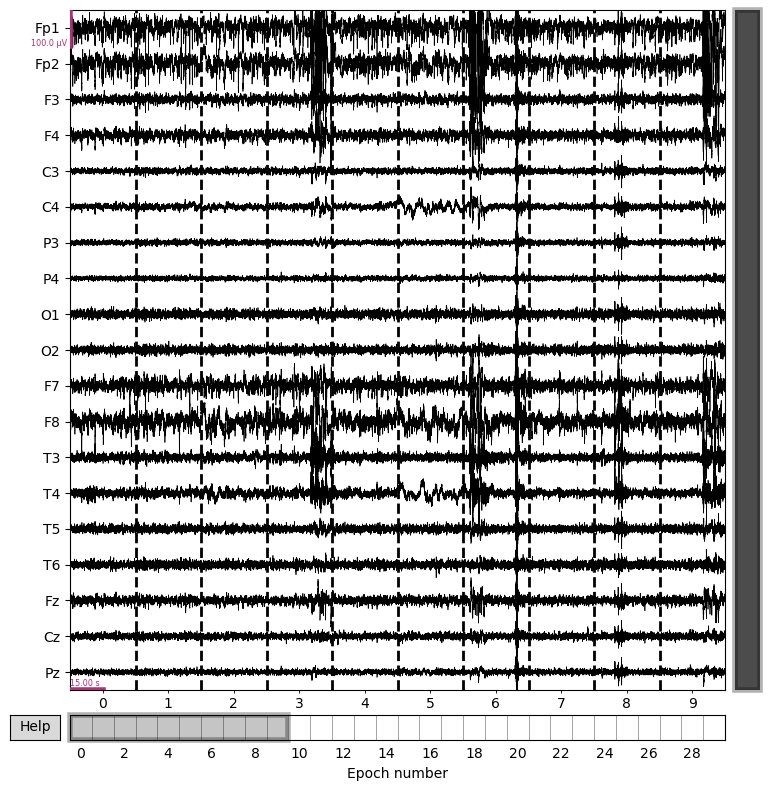

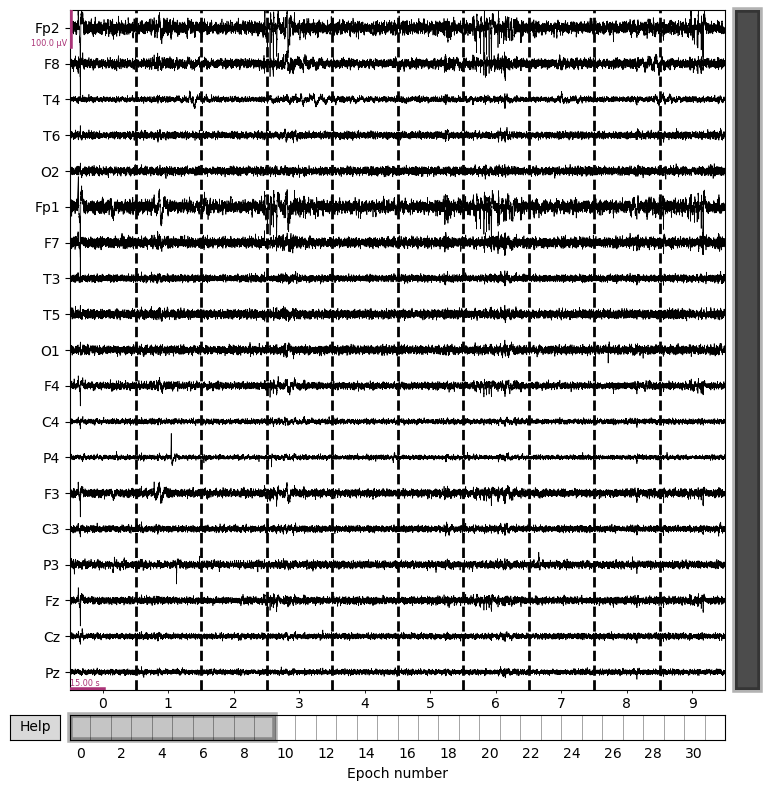

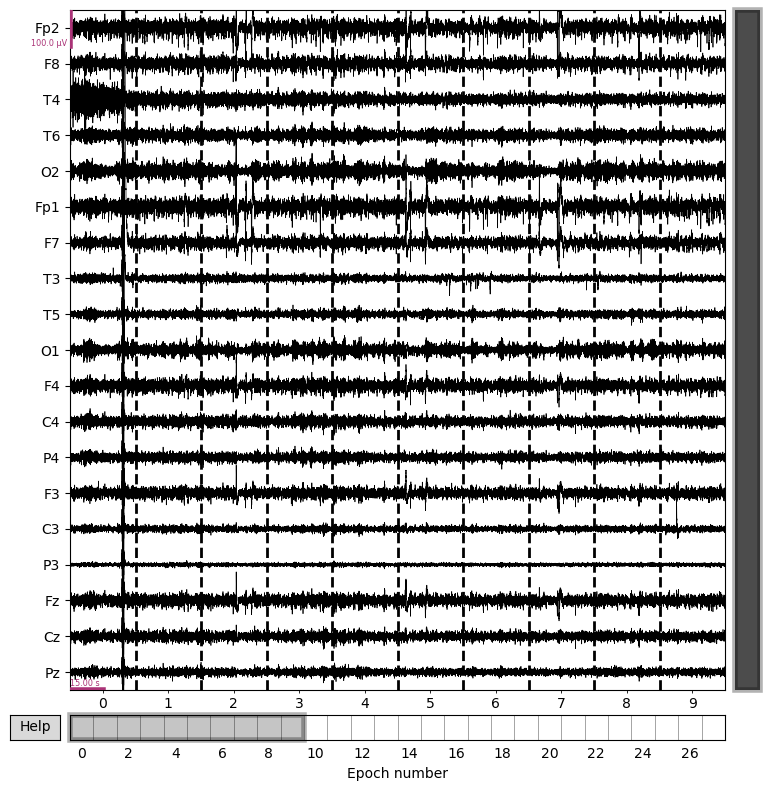

In [9]:
for i in range(14):
    hc_epochs[i].plot(n_epochs=10, scalings=dict(eeg=50e-6), block=True)

In [10]:
for i in range(14):
    scz_epochs[i].drop_bad(reject=dict(eeg=150e-6), flat=dict(eeg=1e-6))
    hc_epochs[i].drop_bad(reject=dict(eeg=150e-6), flat=dict(eeg=1e-6))

    Rejecting  epoch based on EEG : ['Fp2', 'Fp1', 'F3']
    Rejecting  epoch based on EEG : ['Fp2', 'Fp1', 'F7', 'F3']
    Rejecting  epoch based on EEG : ['Fp2']
    Rejecting  epoch based on EEG : ['Fp2', 'Fp1']
    Rejecting  epoch based on EEG : ['F8', 'Fp1', 'T3']
5 bad epochs dropped
    Rejecting  epoch based on EEG : ['O2', 'O1']
    Rejecting  epoch based on EEG : ['O2', 'O1']
    Rejecting  epoch based on EEG : ['O2', 'O1']
    Rejecting  epoch based on EEG : ['Fp2', 'O2', 'Fp1', 'O1']
    Rejecting  epoch based on EEG : ['O2']
    Rejecting  epoch based on EEG : ['O2']
    Rejecting  epoch based on EEG : ['Fp2', 'O2', 'Fp1', 'O1']
    Rejecting  epoch based on EEG : ['O2', 'O1']
    Rejecting  epoch based on EEG : ['Fp2', 'O2', 'Fp1']
    Rejecting  epoch based on EEG : ['Fp2', 'Fp1']
    Rejecting  epoch based on EEG : ['Fp2', 'Fp1']
    Rejecting  epoch based on EEG : ['Fp2', 'Fp1', 'F4']
    Rejecting  epoch based on EEG : ['O2', 'O1']
    Rejecting  epoch based on EEG :

In [11]:
def split_30s_to_10s(epochs_30s, sfreq=250):
    #Convert 30-second epochs into 3 consecutive 10-second epochs
    data=epochs_30s.get_data()  # (n_epochs, n_ch, n_times)

    samples_10s=int(10 * sfreq)
    epochs_10s=[]

    for ep in data:
        epochs_10s.append(ep[:, 0:samples_10s])
        epochs_10s.append(ep[:, samples_10s:2*samples_10s])
        epochs_10s.append(ep[:, 2*samples_10s:3*samples_10s])

    epochs_10s=np.array(epochs_10s)

    return mne.EpochsArray(epochs_10s, epochs_30s.info, tmin=0)

scz_epochs1=[]
hc_epochs1=[]

for i in range(14):
    #SCZ
    epochs_10s=split_30s_to_10s(scz_epochs[i], sfreq=250)
    scz_epochs1.append(epochs_10s)

    #HC
    epochs_10s=split_30s_to_10s(hc_epochs[i], sfreq=250)
    hc_epochs1.append(epochs_10s)

Not setting metadata
69 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
30 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
66 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
69 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
81 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
63 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
72 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
51 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
51 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
51 matching events found


In [12]:
print("SCZ 30s epochs:", len(scz_epochs[0]))
print("SCZ 10s epochs:", len(scz_epochs1[0]))

print("HC 30s epochs:", len(hc_epochs[0]))
print("HC 10s epochs:", len(hc_epochs1[0]))

SCZ 30s epochs: 23
SCZ 10s epochs: 69
HC 30s epochs: 10
HC 10s epochs: 30


NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().
    Using multitaper spectrum estimation with 7 DPSS windows
Plotting power spectral density (dB=True).
Averaging across epochs before plotting...
NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().
    Using multitaper spectrum estimation with 7 DPSS windows
Plotting power spectral density (dB=True).


C:\Users\Tanusree\.conda\envs\tanusree_env\lib\site-packages\mne\viz\utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


Averaging across epochs before plotting...
NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().
    Using multitaper spectrum estimation with 7 DPSS windows


C:\Users\Tanusree\.conda\envs\tanusree_env\lib\site-packages\mne\viz\utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


Plotting power spectral density (dB=True).
Averaging across epochs before plotting...
NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().
    Using multitaper spectrum estimation with 7 DPSS windows


C:\Users\Tanusree\.conda\envs\tanusree_env\lib\site-packages\mne\viz\utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


Plotting power spectral density (dB=True).
Averaging across epochs before plotting...
NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().
    Using multitaper spectrum estimation with 7 DPSS windows


C:\Users\Tanusree\.conda\envs\tanusree_env\lib\site-packages\mne\viz\utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


Plotting power spectral density (dB=True).
Averaging across epochs before plotting...
NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().
    Using multitaper spectrum estimation with 7 DPSS windows


C:\Users\Tanusree\.conda\envs\tanusree_env\lib\site-packages\mne\viz\utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


Plotting power spectral density (dB=True).
Averaging across epochs before plotting...
NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().
    Using multitaper spectrum estimation with 7 DPSS windows


C:\Users\Tanusree\.conda\envs\tanusree_env\lib\site-packages\mne\viz\utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


Plotting power spectral density (dB=True).
Averaging across epochs before plotting...
NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().
    Using multitaper spectrum estimation with 7 DPSS windows


C:\Users\Tanusree\.conda\envs\tanusree_env\lib\site-packages\mne\viz\utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


Plotting power spectral density (dB=True).
Averaging across epochs before plotting...
NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().
    Using multitaper spectrum estimation with 7 DPSS windows


C:\Users\Tanusree\.conda\envs\tanusree_env\lib\site-packages\mne\viz\utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


Plotting power spectral density (dB=True).
Averaging across epochs before plotting...
NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().
    Using multitaper spectrum estimation with 7 DPSS windows


C:\Users\Tanusree\.conda\envs\tanusree_env\lib\site-packages\mne\viz\utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


Plotting power spectral density (dB=True).
Averaging across epochs before plotting...
NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().
    Using multitaper spectrum estimation with 7 DPSS windows
Plotting power spectral density (dB=True).
Averaging across epochs before plotting...


C:\Users\Tanusree\.conda\envs\tanusree_env\lib\site-packages\mne\viz\utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().
    Using multitaper spectrum estimation with 7 DPSS windows


C:\Users\Tanusree\.conda\envs\tanusree_env\lib\site-packages\mne\viz\utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


Plotting power spectral density (dB=True).
Averaging across epochs before plotting...
NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().
    Using multitaper spectrum estimation with 7 DPSS windows


C:\Users\Tanusree\.conda\envs\tanusree_env\lib\site-packages\mne\viz\utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


Plotting power spectral density (dB=True).
Averaging across epochs before plotting...
NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().
    Using multitaper spectrum estimation with 7 DPSS windows


C:\Users\Tanusree\.conda\envs\tanusree_env\lib\site-packages\mne\viz\utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


Plotting power spectral density (dB=True).
Averaging across epochs before plotting...
NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().
    Using multitaper spectrum estimation with 7 DPSS windows


C:\Users\Tanusree\.conda\envs\tanusree_env\lib\site-packages\mne\viz\utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


Plotting power spectral density (dB=True).
Averaging across epochs before plotting...
NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().
    Using multitaper spectrum estimation with 7 DPSS windows


C:\Users\Tanusree\.conda\envs\tanusree_env\lib\site-packages\mne\viz\utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


Plotting power spectral density (dB=True).
Averaging across epochs before plotting...
NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().
    Using multitaper spectrum estimation with 7 DPSS windows


C:\Users\Tanusree\.conda\envs\tanusree_env\lib\site-packages\mne\viz\utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


Plotting power spectral density (dB=True).
Averaging across epochs before plotting...
NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().
    Using multitaper spectrum estimation with 7 DPSS windows


C:\Users\Tanusree\.conda\envs\tanusree_env\lib\site-packages\mne\viz\utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


Plotting power spectral density (dB=True).
Averaging across epochs before plotting...
NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().
    Using multitaper spectrum estimation with 7 DPSS windows


C:\Users\Tanusree\.conda\envs\tanusree_env\lib\site-packages\mne\viz\utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


Plotting power spectral density (dB=True).
Averaging across epochs before plotting...
NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().
    Using multitaper spectrum estimation with 7 DPSS windows


C:\Users\Tanusree\.conda\envs\tanusree_env\lib\site-packages\mne\viz\utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


Plotting power spectral density (dB=True).
Averaging across epochs before plotting...
NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().
    Using multitaper spectrum estimation with 7 DPSS windows


C:\Users\Tanusree\.conda\envs\tanusree_env\lib\site-packages\mne\viz\utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


Plotting power spectral density (dB=True).
Averaging across epochs before plotting...
NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().
    Using multitaper spectrum estimation with 7 DPSS windows


C:\Users\Tanusree\.conda\envs\tanusree_env\lib\site-packages\mne\viz\_mpl_figure.py:2360: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig = plt.figure(FigureClass=FigureClass, **kwargs)
C:\Users\Tanusree\.conda\envs\tanusree_env\lib\site-packages\mne\viz\utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


Plotting power spectral density (dB=True).
Averaging across epochs before plotting...
NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().
    Using multitaper spectrum estimation with 7 DPSS windows
Plotting power spectral density (dB=True).
Averaging across epochs before plotting...
NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().
    Using multitaper spectrum estimation with 7 DPSS windows


C:\Users\Tanusree\.conda\envs\tanusree_env\lib\site-packages\mne\viz\utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)
C:\Users\Tanusree\.conda\envs\tanusree_env\lib\site-packages\mne\viz\utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


Plotting power spectral density (dB=True).
Averaging across epochs before plotting...
NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().
    Using multitaper spectrum estimation with 7 DPSS windows


C:\Users\Tanusree\.conda\envs\tanusree_env\lib\site-packages\mne\viz\utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


Plotting power spectral density (dB=True).
Averaging across epochs before plotting...
NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().
    Using multitaper spectrum estimation with 7 DPSS windows


C:\Users\Tanusree\.conda\envs\tanusree_env\lib\site-packages\mne\viz\utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


Plotting power spectral density (dB=True).
Averaging across epochs before plotting...
NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().
    Using multitaper spectrum estimation with 7 DPSS windows


C:\Users\Tanusree\.conda\envs\tanusree_env\lib\site-packages\mne\viz\utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


Plotting power spectral density (dB=True).
Averaging across epochs before plotting...
NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().
    Using multitaper spectrum estimation with 7 DPSS windows


C:\Users\Tanusree\.conda\envs\tanusree_env\lib\site-packages\mne\viz\utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


Plotting power spectral density (dB=True).
Averaging across epochs before plotting...


C:\Users\Tanusree\.conda\envs\tanusree_env\lib\site-packages\mne\viz\utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


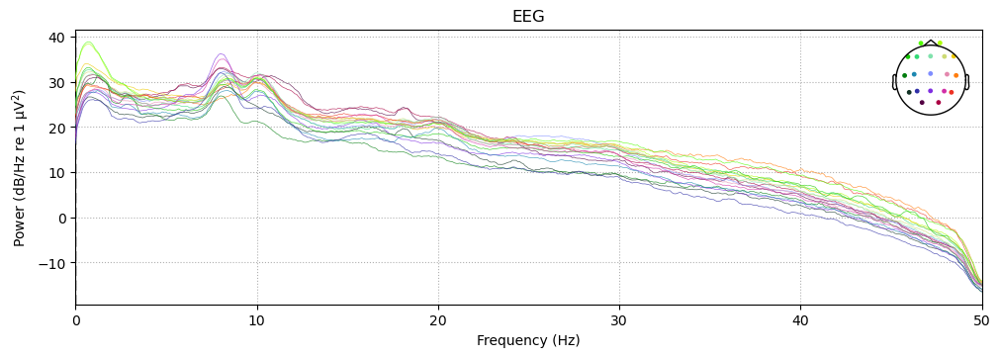

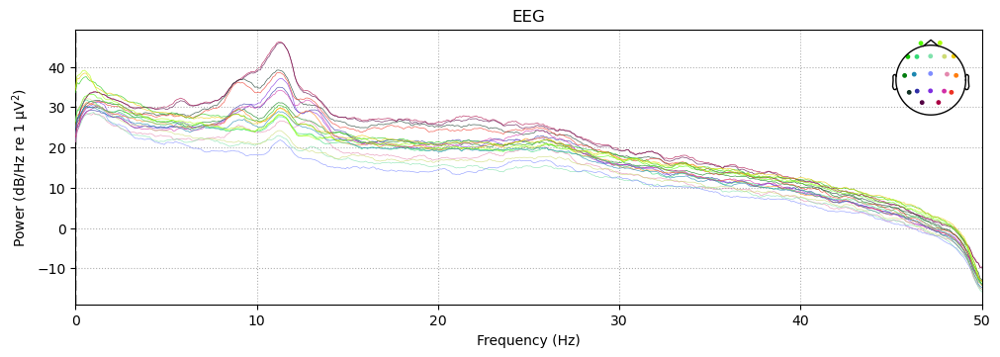

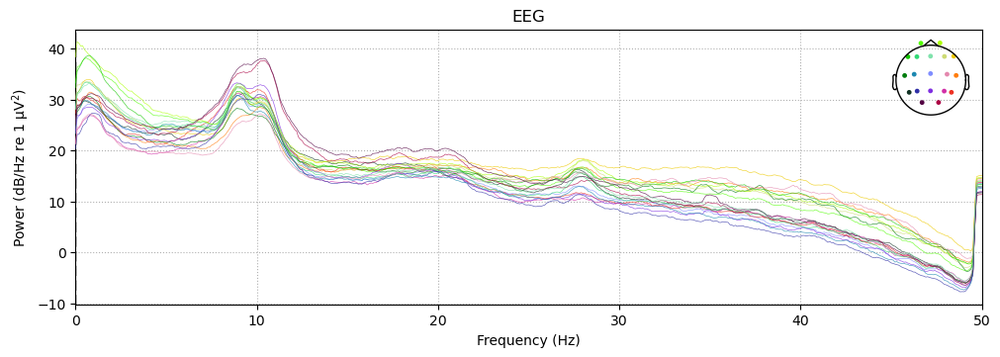

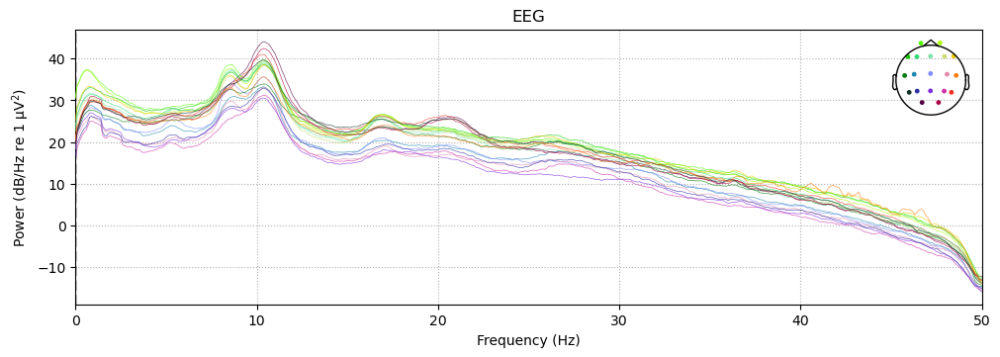

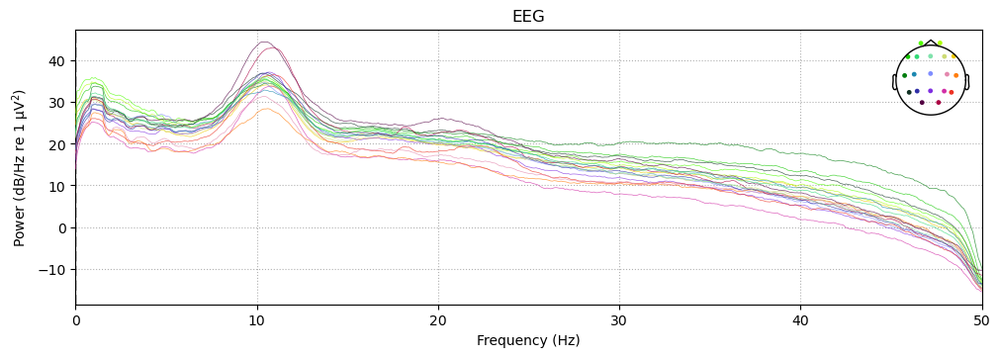

...

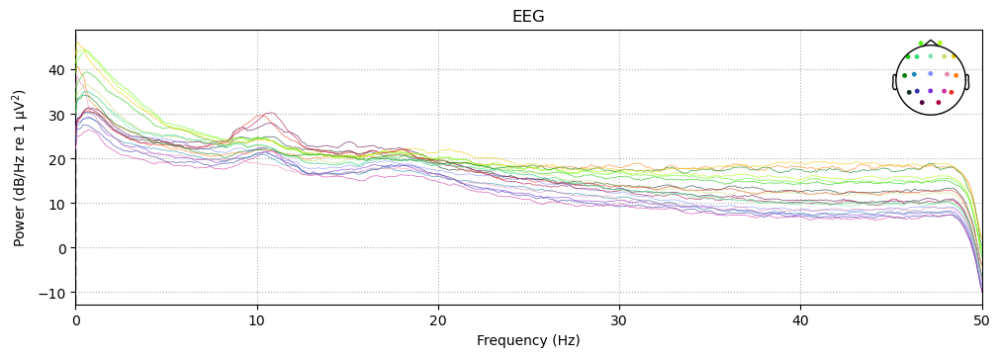

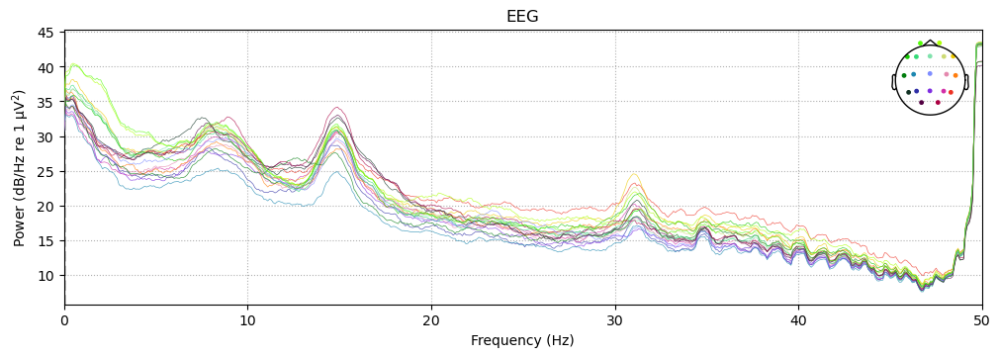

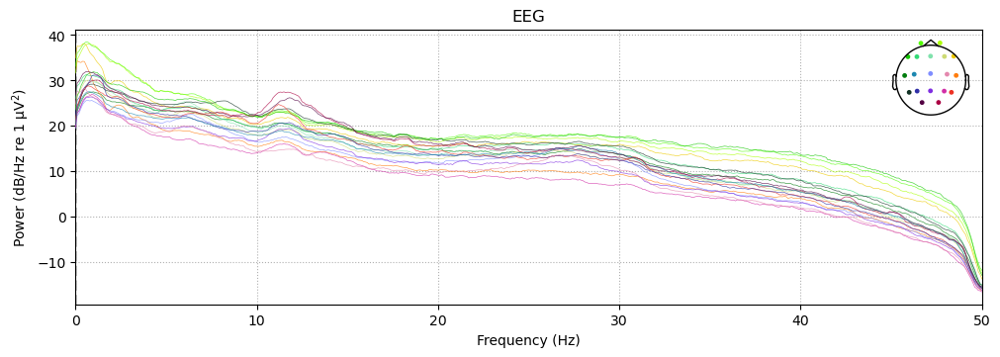

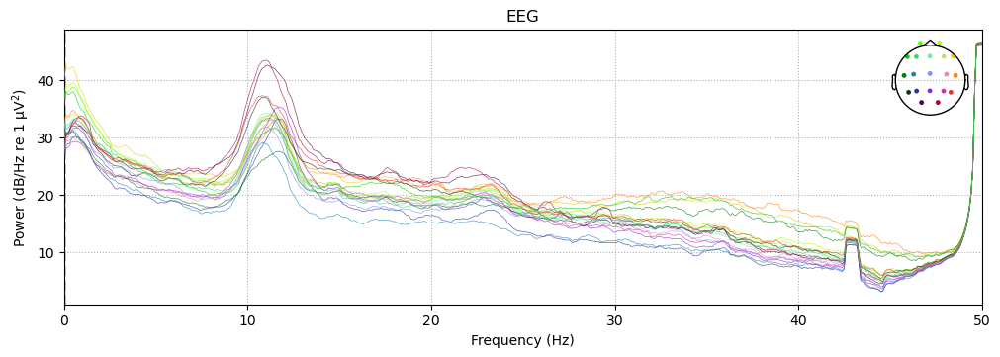

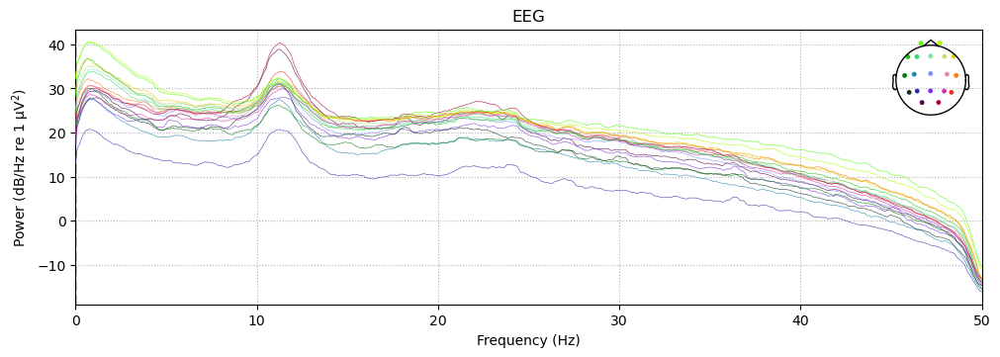

In [13]:
for i in range(14):
    scz_epochs1[i].plot_psd(fmax=50)
    hc_epochs1[i].plot_psd(fmax=50)

In [14]:
bands={
    "delta": (0.5, 3.5),
    "theta": (4, 7.5),
    "alpha": (8, 12.5),
    "beta": (13, 29.5),
    "gamma": (30, 45)
}

In [15]:
scz_epochs_band=[]

for subj_epochs in scz_epochs1:
    band_dict={}

    for band, (l_freq, h_freq) in bands.items():
        band_dict[band]=subj_epochs.copy().filter(l_freq=l_freq, h_freq=h_freq, method="iir", iir_params=dict(order=5, ftype="butter"))

    scz_epochs_band.append(band_dict)

hc_epochs_band=[]

for subj_epochs in hc_epochs1:
    band_dict={}

    for band, (l_freq, h_freq) in bands.items():
        band_dict[band]=subj_epochs.copy().filter(l_freq=l_freq, h_freq=h_freq,  method="iir", iir_params=dict(order=5, ftype="butter"))

    hc_epochs_band.append(band_dict)

Setting up band-pass filter from 0.5 - 3.5 Hz

IIR filter parameters
---------------------
Butterworth bandpass zero-phase (two-pass forward and reverse) non-causal filter:
- Filter order 20 (effective, after forward-backward)
- Cutoffs at 0.50, 3.50 Hz: -6.02, -6.02 dB

Setting up band-pass filter from 4 - 7.5 Hz

IIR filter parameters
---------------------
Butterworth bandpass zero-phase (two-pass forward and reverse) non-causal filter:
- Filter order 20 (effective, after forward-backward)
- Cutoffs at 4.00, 7.50 Hz: -6.02, -6.02 dB

Setting up band-pass filter from 8 - 12 Hz

IIR filter parameters
---------------------
Butterworth bandpass zero-phase (two-pass forward and reverse) non-causal filter:
- Filter order 20 (effective, after forward-backward)
- Cutoffs at 8.00, 12.50 Hz: -6.02, -6.02 dB

Setting up band-pass filter from 13 - 30 Hz

IIR filter parameters
---------------------
Butterworth bandpass zero-phase (two-pass forward and reverse) non-causal filter:
- Filter order 20

In [16]:
for i in range(14):
    print(i, {band: len(scz_epochs_band[i][band]) for band in bands})
    print(i, {band: len(hc_epochs_band[i][band]) for band in bands})

0 {'delta': 69, 'theta': 69, 'alpha': 69, 'beta': 69, 'gamma': 69}
0 {'delta': 30, 'theta': 30, 'alpha': 30, 'beta': 30, 'gamma': 30}
1 {'delta': 66, 'theta': 66, 'alpha': 66, 'beta': 66, 'gamma': 66}
1 {'delta': 69, 'theta': 69, 'alpha': 69, 'beta': 69, 'gamma': 69}
2 {'delta': 81, 'theta': 81, 'alpha': 81, 'beta': 81, 'gamma': 81}
2 {'delta': 63, 'theta': 63, 'alpha': 63, 'beta': 63, 'gamma': 63}
3 {'delta': 72, 'theta': 72, 'alpha': 72, 'beta': 72, 'gamma': 72}
3 {'delta': 51, 'theta': 51, 'alpha': 51, 'beta': 51, 'gamma': 51}
4 {'delta': 51, 'theta': 51, 'alpha': 51, 'beta': 51, 'gamma': 51}
4 {'delta': 51, 'theta': 51, 'alpha': 51, 'beta': 51, 'gamma': 51}
5 {'delta': 12, 'theta': 12, 'alpha': 12, 'beta': 12, 'gamma': 12}
5 {'delta': 69, 'theta': 69, 'alpha': 69, 'beta': 69, 'gamma': 69}
6 {'delta': 45, 'theta': 45, 'alpha': 45, 'beta': 45, 'gamma': 45}
6 {'delta': 63, 'theta': 63, 'alpha': 63, 'beta': 63, 'gamma': 63}
7 {'delta': 57, 'theta': 57, 'alpha': 57, 'beta': 57, 'gamma':

In [17]:
scz_epochs_ref={"CSD": []}
hc_epochs_ref={"CSD": []}

In [18]:
for subj_band_dict in scz_epochs_band:

    # CSD reference
    csd_dict={}
    for band, ep in subj_band_dict.items():
        csd_dict[band]=mne.preprocessing.compute_current_source_density(ep)

    scz_epochs_ref["CSD"].append(csd_dict)

for subj_band_dict in hc_epochs_band:

    # CSD reference
    csd_dict={}
    for band, ep in subj_band_dict.items():
        csd_dict[band]=mne.preprocessing.compute_current_source_density(ep)

    hc_epochs_ref["CSD"].append(csd_dict)

Fitted sphere radius:         95.6 mm
Origin head coordinates:      -0.9 15.8 45.4 mm
Origin device coordinates:    -0.9 15.8 45.4 mm
Fitted sphere radius:         95.6 mm
Origin head coordinates:      -0.9 15.8 45.4 mm
Origin device coordinates:    -0.9 15.8 45.4 mm
Fitted sphere radius:         95.6 mm
Origin head coordinates:      -0.9 15.8 45.4 mm
Origin device coordinates:    -0.9 15.8 45.4 mm
Fitted sphere radius:         95.6 mm
Origin head coordinates:      -0.9 15.8 45.4 mm
Origin device coordinates:    -0.9 15.8 45.4 mm
Fitted sphere radius:         95.6 mm
Origin head coordinates:      -0.9 15.8 45.4 mm
Origin device coordinates:    -0.9 15.8 45.4 mm
Fitted sphere radius:         95.6 mm
Origin head coordinates:      -0.9 15.8 45.4 mm
Origin device coordinates:    -0.9 15.8 45.4 mm
Fitted sphere radius:         95.6 mm
Origin head coordinates:      -0.9 15.8 45.4 mm
Origin device coordinates:    -0.9 15.8 45.4 mm
Fitted sphere radius:         95.6 mm
Origin head coordinates:

In [19]:
print(type(scz_epochs_ref["CSD"][0]["alpha"]))
print(type(hc_epochs_ref["CSD"][0]["alpha"]))

<class 'mne.epochs.EpochsArray'>
<class 'mne.epochs.EpochsArray'>


In [20]:
import numpy as np


def symbolize(data, n_bins=3):
    """
    Convert a signal into discrete states: 0, 1, ..., n_bins-1.

    Equal-width bins are defined separately for each input signal
    using that signal's minimum and maximum.
    """
    data = np.asarray(data, dtype=np.float64)

    if not np.all(np.isfinite(data)):
        raise ValueError("Signal contains NaN or infinite values.")

    data_min = np.min(data)
    data_max = np.max(data)

    if np.isclose(data_min, data_max):
        return np.zeros(len(data), dtype=np.int32)

    edges = np.linspace(data_min, data_max, n_bins + 1)

    # Produces states from 0 to n_bins-1
    symbols = np.digitize(data, edges[1:-1])

    return symbols.astype(np.int32)


def compute_te_pair(x, y, lag=1, n_bins=3):
    """
    Estimate transfer entropy X -> Y:

    TE(X -> Y) = sum p(y_future, y_past, x_past) *
        log2[P(y_future | y_past, x_past) /
             P(y_future | y_past)]

    x_past = x[t-lag]
    y_past = y[t]
    y_future = y[t+1]

    Parameters
    ----------
    x, y : array-like
        Signals for two channels in one window.
    lag : int
        Lag for the source past.
    n_bins : int
        Number of discrete states.

    Returns
    -------
    te : float
        Estimated transfer entropy in bits.
    """
    x = np.asarray(x, dtype=np.float64)
    y = np.asarray(y, dtype=np.float64)

    if len(x) != len(y):
        raise ValueError("Signals x and y must have equal lengths.")

    if lag < 1:
        raise ValueError("lag must be at least 1.")

    if n_bins < 2:
        raise ValueError("n_bins must be at least 2.")

    if len(x) <= lag + 1:
        raise ValueError("Signals are too short for the selected lag.")

    # Convert signals to discrete states
    x_sym = symbolize(x, n_bins)
    y_sym = symbolize(y, n_bins)

    # Observations:
    # x_past = x[t-lag]
    # y_past = y[t]
    # y_future = y[t+1]
    x_past = x_sym[:-lag-1]
    y_past = y_sym[lag:-1]
    y_future = y_sym[lag+1:]

    n = len(y_future)

    # Count joint occurrences
    count_xyz = {}
    count_yx = {}
    count_yy = {}

    for xf, yp, yf in zip(x_past, y_past, y_future):
        key_xyz = (yf, yp, xf)
        key_yx = (yp, xf)
        key_yy = (yf, yp)

        count_xyz[key_xyz] = count_xyz.get(key_xyz, 0) + 1
        count_yx[key_yx] = count_yx.get(key_yx, 0) + 1
        count_yy[key_yy] = count_yy.get(key_yy, 0) + 1

    # Marginal counts for conditioning probabilities
    count_yp_xp = {}
    count_yp = {}

    for xf, yp in zip(x_past, y_past):
        key = (yp, xf)
        count_yp_xp[key] = count_yp_xp.get(key, 0) + 1
        count_yp[yp] = count_yp.get(yp, 0) + 1

    te = 0.0

    for (yf, yp, xf), count in count_xyz.items():

        # P(y_future, y_past, x_past)
        p_xyz = count / n

        # P(y_future | y_past, x_past)
        p_yf_given_yp_xp = count / count_yp_xp[(yp, xf)]

        # P(y_future | y_past)
        p_yf_given_yp = count_yy[(yf, yp)] / count_yp[yp]

        if p_yf_given_yp_xp > 0 and p_yf_given_yp > 0:
            te += p_xyz * np.log2(
                p_yf_given_yp_xp / p_yf_given_yp
            )

    # Small negative values can arise from numerical precision.
    return float(max(te, 0.0))


def compute_te_matrix(data, lag=1, n_bins=3):
    """
    Compute directed TE for every ordered channel pair.

    data shape: (n_channels, n_times)
    TE[i, j] represents channel i -> channel j.
    """
    data = np.asarray(data, dtype=np.float64)

    if data.ndim != 2:
        raise ValueError("data must have shape (n_channels, n_times).")

    n_channels, _ = data.shape

    te_matrix = np.zeros(
        (n_channels, n_channels),
        dtype=np.float32
    )

    for i in range(n_channels):
        for j in range(n_channels):
            if i == j:
                continue

            te_matrix[i, j] = compute_te_pair(
                data[i],
                data[j],
                lag=lag,
                n_bins=n_bins
            )

    return te_matrix


def sliding_window_fc(
    epoch,
    sfreq=250,
    win_sec=2.0,
    step_sec=1.0,
    lag=1,
    n_bins=3
):
    """
    Compute directed TE matrices using sliding windows.

    epoch shape: (n_channels, n_times)
    output shape: (n_windows, n_channels, n_channels)
    """
    epoch = np.asarray(epoch, dtype=np.float64)

    win = int(round(win_sec * sfreq))
    step = int(round(step_sec * sfreq))

    if win <= 0 or step <= 0:
        raise ValueError("Window and step lengths must be positive.")

    n_channels, n_times = epoch.shape

    if n_times < win:
        raise ValueError("Epoch is shorter than the requested window.")

    starts = range(0, n_times - win + 1, step)

    te_windows = []

    for start in starts:
        segment = epoch[:, start:start + win]

        te_matrix = compute_te_matrix(
            segment,
            lag=lag,
            n_bins=n_bins
        )

        np.fill_diagonal(te_matrix, 0.0)
        te_windows.append(te_matrix)

    return np.asarray(te_windows, dtype=np.float32)

In [21]:
def compute_subject_dfc(
    subj_dict,
    sfreq=250,
    win_sec=2.0,
    step_sec=1.0,
    lag=1,
    n_bins=3
):
    band_dfc = {}

    for band, epochs in subj_dict.items():
        data = epochs.get_data().astype(np.float32)

        n_epochs, n_channels, n_times = data.shape
        win = int(round(win_sec * sfreq))
        step = int(round(step_sec * sfreq))
        n_win = (n_times - win) // step + 1

        te_all = np.empty(
            (n_epochs * n_win, n_channels, n_channels),
            dtype=np.float32
        )

        idx = 0

        for ep in data:
            te_windows = sliding_window_fc(
                ep,
                sfreq=sfreq,
                win_sec=win_sec,
                step_sec=step_sec,
                lag=lag,
                n_bins=n_bins
            )

            n_w = len(te_windows)
            te_all[idx:idx + n_w] = te_windows
            idx += n_w

        band_dfc[band] = te_all

    return band_dfc

In [ ]:
import numpy as np

# ---------------------------------------------------------
# 1. Compute dynamic dDTF for all subjects
#    Assumes compute_subject_dfc() is already defined
#    to calculate dDTF for each frequency band and window.
# ---------------------------------------------------------

scz_ddtf = [
    compute_subject_dfc(subject)
    for subject in scz_epochs_ref["CSD"]
]

hc_ddtf = [
    compute_subject_dfc(subject)
    for subject in hc_epochs_ref["CSD"]
]

print("Dynamic dDTF computation completed.")
print("SCZ subjects:", len(scz_ddtf))
print("HC subjects:", len(hc_ddtf))


# ---------------------------------------------------------
# 2. Validate the computed results
# ---------------------------------------------------------

if len(scz_ddtf) == 0 or len(hc_ddtf) == 0:
    raise ValueError("SCZ or HC dDTF results are empty.")

bands = ["delta", "theta", "alpha", "beta", "gamma"]

for group_name, group_results in [
    ("SCZ", scz_ddtf),
    ("HC", hc_ddtf)
]:
    print(f"\n{'=' * 55}")
    print(f"{group_name} dDTF validation")
    print(f"{'=' * 55}")

    for band in bands:
        if band not in group_results[0]:
            raise KeyError(
                f"Frequency band '{band}' is missing from {group_name} results."
            )

        matrices = [
            np.asarray(subject_result[band], dtype=np.float64)
            for subject_result in group_results
        ]

        # Expected structure: (number of windows, channels, channels)
        for subject_idx, subject_matrices in enumerate(matrices):
            if subject_matrices.ndim != 3:
                raise ValueError(
                    f"{group_name}, subject {subject_idx + 1}, band {band}: "
                    f"expected 3D array (windows, channels, channels), "
                    f"got {subject_matrices.shape}"
                )

            if subject_matrices.shape[1] != subject_matrices.shape[2]:
                raise ValueError(
                    f"{group_name}, subject {subject_idx + 1}, band {band}: "
                    f"connectivity matrices are not square: "
                    f"{subject_matrices.shape}"
                )

        all_values = np.concatenate([
            matrix.ravel() for matrix in matrices
        ])

        if not np.isfinite(all_values).all():
            raise ValueError(
                f"Non-finite dDTF values found in {group_name}, band {band}."
            )

        print(
            f"{band.capitalize():<7} | "
            f"First subject shape: {matrices[0].shape} | "
            f"Range: [{all_values.min():.6f}, {all_values.max():.6f}] | "
            f"Finite: {np.isfinite(all_values).all()}"
        )


# ---------------------------------------------------------
# 3. Inspect one example dDTF matrix
# ---------------------------------------------------------

example_ddtf = np.asarray(
    scz_ddtf[0]["alpha"][0],
    dtype=np.float64
)

print("\nExample SCZ alpha dDTF matrix")
print("Matrix shape:", example_ddtf.shape)
print("Minimum:", example_ddtf.min())
print("Maximum:", example_ddtf.max())
print("Diagonal:", np.diag(example_ddtf))
print("All values finite:", np.isfinite(example_ddtf).all())


# ---------------------------------------------------------
# 4. Check diagonal values explicitly
# ---------------------------------------------------------

diagonal_values = np.diagonal(
    np.asarray(scz_ddtf[0]["alpha"], dtype=np.float64),
    axis1=1,
    axis2=2
)

print(
    "Maximum absolute diagonal value across the first SCZ subject's "
    "alpha windows:",
    np.max(np.abs(diagonal_values))
)

In [ ]:
'''base_dir = r"H:\Features\TE_Class\sTE_matrix"
bands_list = list(bands.keys())

# ===================== CREATE FOLDERS =====================
for band in bands_list:
    os.makedirs(f"{base_dir}/{band}/SCZ", exist_ok=True)
    os.makedirs(f"{base_dir}/{band}/HC", exist_ok=True)

# ===================== SAVE MATRICES =====================
def save_group_matrices(dfc, group_name):
    for subj_id, subj in enumerate(dfc):
        for band in bands_list:
            for win_id, fc in enumerate(subj[band]):

                # File name (same pattern as images)
                fname = f"subj{subj_id:03d}_win{win_id:04d}.npy"

                # Save matrix
                np.save(
                    os.path.join(base_dir, band, group_name, fname),
                    fc.astype(np.float32)
                )

# ===================== CALL =====================
save_group_matrices(scz_dfc, "SCZ")
save_group_matrices(hc_dfc, "HC")

print("✅ Matrix data saved successfully!")'''

In [ ]:
'''def load_group_matrices(base_dir, bands_list, group_name):
    subjects = {}

    for band in bands_list:
        band_dir = os.path.join(base_dir, band, group_name)

        for fname in sorted(os.listdir(band_dir)):
            if not fname.endswith(".npy"):
                continue

            name = fname[:-4]
            subj_part, _ = name.split("_")
            subj_id = int(subj_part[4:])

            mat = np.load(os.path.join(band_dir, fname))

            if subj_id not in subjects:
                subjects[subj_id] = {}

            subjects[subj_id].setdefault(band, []).append(mat)

    # Convert to structured list
    all_subjects = []
    for subj_id in sorted(subjects):
        subj_dict = {}
        for band in bands_list:
            subj_dict[band] = np.stack(subjects[subj_id][band])
        all_subjects.append(subj_dict)

    return all_subjects'''

In [ ]:
scz_dfc[0]['alpha'].shape

In [ ]:
epochs=scz_epochs_ref["CSD"][0]["alpha"]
print(epochs.get_data().shape)
# (n_epochs, n_channels, n_times)
for i, subj in enumerate(hc_epochs_ref["CSD"]):
    epochs=subj["alpha"]
    n_epochs, n_ch, n_times=epochs.get_data().shape

    win=int(2.0 * 250)
    step=int(1.0 * 250)
    n_win_ep=(n_times - win) // step + 1

    print(
        f"Subject {i:02d} | "
        f"epochs={n_epochs:2d} | "
        f"windows/epoch={n_win_ep:2d} | "
        f"total windows={n_epochs * n_win_ep:3d}"
    )

In [ ]:
def count_windows_per_subject(epochs, sfreq=250, win_sec=2.0, step_sec=1.0):
    data=epochs.get_data()  # (n_epochs, n_ch, n_times)
    n_epochs, _, n_times=data.shape

    win=int(win_sec * sfreq)
    step=int(step_sec * sfreq)

    n_win_epoch=(n_times - win) // step + 1
    n_total=n_epochs * n_win_epoch

    return n_epochs, n_win_epoch, n_total

epochs=scz_epochs_ref["CSD"][0]["alpha"]

n_ep, n_win_ep, n_total=count_windows_per_subject(epochs)

print("Epochs              :", n_ep)
print("Windows per epoch   :", n_win_ep)
print("Total windows       :", n_total)

In [ ]:
def plot_dfc_scz_vs_hc(
    scz_dfc, hc_dfc,
    scz_epochs_ref, hc_epochs_ref,
    subj_idx=0,
    band="alpha",
    n_windows=5
):
    """
    Plot SCZ vs HC dynamic FC matrices side-by-side
    """

    #Extract DFC matrices
    scz_mat=scz_dfc[subj_idx][band]
    hc_mat=hc_dfc[subj_idx][band]

    n_windows=min(n_windows, scz_mat.shape[0], hc_mat.shape[0])

    ch_names=scz_epochs_ref["CSD"][subj_idx][band].ch_names

    #Global color scaling for fair comparison
    vmin=min(scz_mat[:n_windows].min(), hc_mat[:n_windows].min())
    vmax=max(scz_mat[:n_windows].max(), hc_mat[:n_windows].max())

    fig, axes=mp.subplots(
        2, n_windows,
        figsize=(4*n_windows, 8),
        constrained_layout=True
    )

    for w in range(n_windows):
        # --- SCZ ---
        im=axes[0, w].imshow(scz_mat[w], cmap="hot", vmin=vmin, vmax=vmax)
        axes[0, w].set_title(f"SCZ | Window {w+1}")
        axes[0, w].set_xticks(range(len(ch_names)))
        axes[0, w].set_yticks(range(len(ch_names)))
        axes[0, w].set_xticklabels(ch_names, rotation=90, fontsize=8)
        axes[0, w].set_yticklabels(ch_names, fontsize=8)

        # --- HC ---
        axes[1, w].imshow(hc_mat[w], cmap="hot", vmin=vmin, vmax=vmax)
        axes[1, w].set_title(f"HC | Window {w+1}")
        axes[1, w].set_xticks(range(len(ch_names)))
        axes[1, w].set_yticks(range(len(ch_names)))
        axes[1, w].set_xticklabels(ch_names, rotation=90, fontsize=8)
        axes[1, w].set_yticklabels(ch_names, fontsize=8)

    #Shared colorbar
    cbar=fig.colorbar(im, ax=axes, fraction=0.02, pad=0.02)
    cbar.set_label("AEC")

    fig.suptitle(f"Dynamic Functional Connectivity (Band: {band.upper()}, Subject {subj_idx})",
        fontsize=16)

    mp.show()

In [ ]:
plot_dfc_scz_vs_hc(
    scz_dfc=scz_dfc,
    hc_dfc=hc_dfc,
    scz_epochs_ref=scz_epochs_ref,
    hc_epochs_ref=hc_epochs_ref,
    subj_idx=0,
    band="alpha",
    n_windows=5
)

In [ ]:
base_dir=r"H:\Features1\MVAR_Class\TE"
bands_list=list(bands.keys())

for band in bands_list:
    os.makedirs(f"{base_dir}/{band}/SCZ", exist_ok=True)
    os.makedirs(f"{base_dir}/{band}/HC", exist_ok=True)

In [ ]:
def summarize_mapping(scz_dfc, hc_dfc, bands_list, measure_name):
    # Collect original connectivity values across both groups,
    # all subjects, all frequency bands, and all windows.
    chunks = []

    for group in (scz_dfc, hc_dfc):
        for subject in group:
            for band in bands_list:
                matrices = np.asarray(subject[band])

                for matrix in matrices:
                    chunks.append(
                        np.asarray(matrix, dtype=np.float64).ravel()
                    )

    if not chunks:
        raise ValueError(f"No matrices found for {measure_name}")

    x = np.concatenate(chunks)

    # Do not silently discard invalid values.
    invalid_count = int((~np.isfinite(x)).sum())
    if invalid_count:
        raise ValueError(
            f"{measure_name}: found {invalid_count} non-finite values. "
            "Investigate them before calculating mapping statistics."
        )

    # Empirical range and percentiles BEFORE clipping.
    minimum = float(np.min(x))
    maximum = float(np.max(x))
    p01, p99 = np.percentile(x, [1, 99])

    # Clipping fractions, calculated from the original values.
    below_pct = 100 * np.mean(x < -1)
    above_pct = 100 * np.mean(x > 1)
    total_clipped_pct = below_pct + above_pct

    # Reproduce the exact mapping used by fc_to_pil_image().
    clipped = np.clip(x, -1, 1)
    grey = ((clipped + 1) / 2 * 255).astype(np.uint8)

    # Count grayscale levels after mapping but before resizing.
    distinct_levels = int(np.unique(grey).size)

    return {
        "Measure": measure_name,
        "Number of values": int(x.size),
        "Minimum": minimum,
        "1st percentile": float(p01),
        "99th percentile": float(p99),
        "Maximum": maximum,
        "Below -1 (%)": float(below_pct),
        "Above +1 (%)": float(above_pct),
        "Total clipped (%)": float(total_clipped_pct),
        "Distinct grayscale levels (before resize)": distinct_levels,
    }


# Summarize sTE mapping statistics.
sTE_stats = summarize_mapping(
    scz_dfc,
    hc_dfc,
    bands_list,
    measure_name="sTE"
)

summary_df = pd.DataFrame([sTE_stats])

print(summary_df.to_string(index=False))

# Save the statistics.
# summary_df.to_csv("sTE_mapping_statistics.csv", index=False)

In [164]:
def fc_to_pil_image(fc, size=128):
    fc=np.clip(fc, -1, 1)
    fc_uint8=((fc+1)/2 * 255).astype(np.uint8)
    img=Image.fromarray(fc_uint8, mode='L')
    img=img.resize((size,size), resample=Image.BILINEAR)
    return img

In [165]:
def save_group_images(dfc, group_name):
    for subj_id, subj in enumerate(dfc):
        for band in bands_list:
            for win_id, fc in enumerate(subj[band]):
                img=fc_to_pil_image(fc)
                fname=f"subj{subj_id:03d}_win{win_id:04d}.png"
                img.save(os.path.join(base_dir, band, group_name, fname))

save_group_images(scz_dfc, "SCZ")
save_group_images(hc_dfc, "HC")